# Start Here

Welcome to the *Active Learning for bioacoustics* challenge.

This is an example notebook where you can evaluate your sampling method and export results for submissions. *You are free to adjust this notebook, however the results (.yaml) file must retain the correct format*.

Currently, this notebook runs the four baseline sampling strategies:
- `random` -- random sampling (challenge baseline)
- `margin_multilabel` -- uncertainty-based margin sampling
- `sklearn_coreset` -- diversity-based coreset selection
- `sklearn_typiclust` -- typicality clustering

**AULC** (Area Under the Learning Curve) for mAP (macro) is the primary metric:


---

**This notebook is a v2 "active testing" preview**, adapted from `biodcase_example.ipynb` to also demonstrate `ValidationStrategy` (random validation-sample selection) and budget allocation between training and validation. Everything below still works exactly like the original when `VALIDATION_ALLOCATION_RATIO = 0.0` -- active testing is off by default and fully backwards compatible. Active-testing fields are **not yet part of the official submission YAML schema** (that's a later step); this notebook only demonstrates the underlying mechanics.

In [1]:
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
import time

PROJECT_ROOT = Path().absolute().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from core.active_learner import ActiveLearner

core.active_learner - INFO - Pre-warming UMAP (triggering numba JIT compilation)...
core.active_learner - INFO - UMAP pre-warming completed in 6.041451930999756


## Step 1: Setup Configuration

In [2]:
# ---------------------------------------------------------------------------
# Active Learning Configuration
# ---------------------------------------------------------------------------

# Participant info:
AUTHOR_LASTNAME = 'baseline'      # NOTE: Lastname of the corresponding author
INSTITUTE_ABBREVIATION = 'BASEAL' # NOTE: Abbreviation of your institute or None

# AL loop parameters (Baseline default config)
N_CYCLES            = 15
EPOCHS_PER_CYCLE    = 10
BATCH_SIZE          = 32
N_SAMPLES_PER_CYCLE = 50    # NOTE: You can implement a scheduler

# Number of independent full-run repeats (each creates a fresh ActiveLearner
# with random model initialisation). Mean and SD are computed across these runs.
# NOTE: Submitted results must be run with N_REPEATS=5, use a lower value during development.
N_REPEATS = 2

# NOTE: Submitted results must be run with MAX_BUDGET=500.
MAX_BUDGET: int | None = None

# Warm-up samples before the AL loop (None = cold start)
PRETRAIN_SAMPLES: int | None = 50
WARMUP_STRATEGY = "density"  # warmup method: density | random | custom

# --- Active testing (v2 preview) --------------------------------------------
# Validation sampling method -- selects which held-out validation samples to
# reveal for the participant's own performance estimate. Only "random" is
# implemented for now (mirrors SamplingStrategy's "custom" template for
# anything more elaborate).
VALIDATION_STRATEGY = "random"

# Validation is allocated INDEPENDENTLY of training, not carved out of
# N_SAMPLES_PER_CYCLE -- so front-loading validation never crowds out
# training samples in a given cycle. MAX_BUDGET (if set) is the only shared
# constraint across both pools. Set N_VALIDATION_SAMPLES_PER_CYCLE = 0 (and
# leave VALIDATION_SCHEDULER = None) to recover the exact current
# (non-active-testing) behaviour -- no validation samples are ever revealed.
N_VALIDATION_SAMPLES_PER_CYCLE = 100   # NOTE: overridden by VALIDATION_SCHEDULER if set


def validation_scheduler_fixed(n_per_cycle):
    # Reveal a fixed number of validation samples every cycle (equivalent to
    # just setting N_VALIDATION_SAMPLES_PER_CYCLE directly).
    def _sched(cycle_idx, n_validated):
        return n_per_cycle
    return _sched


def validation_scheduler_all_at_start(total):
    # Reveal the entire validation allocation in cycle 0, nothing after --
    # e.g. for participants who want one big, early validation estimate
    # rather than a validation curve that sharpens over cycles.
    def _sched(cycle_idx, n_validated):
        return total if cycle_idx == 0 else 0
    return _sched

# Optional scheduler: a callable (cycle_idx, n_validated_so_far) -> n_to_reveal
# this cycle, mirroring core/baselines/run_evaluation.py's scheduler_* pattern
# for training. Overrides N_VALIDATION_SAMPLES_PER_CYCLE when set. Useful if
# you'd rather reveal validation samples in a different shape than "a fixed
# number every cycle" -- e.g. all at once up front, or back-loaded once the
# model is more mature. Two examples below; write your own the same way.
VALIDATION_SCHEDULER = validation_scheduler_all_at_start(500)


# Baseline strategies to compare. NOTE: When you are ready, add your sampling method here.
STRATEGIES = [
    "random",
    # "margin_multilabel",
    # "sklearn_coreset",
    # "sklearn_typiclust",
]

print(f"Cycles                    : {N_CYCLES}")
print(f"Samples per cycle         : {N_SAMPLES_PER_CYCLE}")
print(f"Epochs per cycle          : {EPOCHS_PER_CYCLE}")
print(f"Outer repeats             : {N_REPEATS}  (independent runs, fresh model init each time)")
print(f"Max budget                : {MAX_BUDGET or 'none'}")
print(f"Strategies                : {STRATEGIES}")
print(f"Validation strategy       : {VALIDATION_STRATEGY}")
if VALIDATION_SCHEDULER is not None:
    print(f"Validation schedule       : custom scheduler")
else:
    print(f"Validation samples/cycle  : {N_VALIDATION_SAMPLES_PER_CYCLE}")

Cycles                    : 15
Samples per cycle         : 50
Epochs per cycle          : 10
Outer repeats             : 2  (independent runs, fresh model init each time)
Max budget                : none
Strategies                : ['random']
Validation strategy       : random
Validation schedule       : custom scheduler


## Step 2: Dataset paths

Set paths for the dataset. Adjust for the BirdSet subsets (HSN, POW, UHH) or ATBFL dataset.

In [3]:
MODEL_NAME     = "perch_v2"  # NOTE: Task 4 datasets will use "perch_v2" 
DATASET_NAME   = "BirdSet_BASEAL/HSN_BASEAL"    # NOTE: download the Task 4 datasets and set the path e.g. "BirdSet_BASEAL/POW_BASEAL"

EMBEDDINGS_DIR = PROJECT_ROOT / DATASET_NAME / "embeddings" / MODEL_NAME
LABELS_PATH    = PROJECT_ROOT / DATASET_NAME / "labels.csv"

print(f"Embeddings : {EMBEDDINGS_DIR}")
print(f"Labels     : {LABELS_PATH}")
print(f"Dataset    : {DATASET_NAME}  |  Model: {MODEL_NAME}")

Embeddings : c:\Users\bmcewen\Documents\GitHub\BaseAL\BirdSet_BASEAL\HSN_BASEAL\embeddings\perch_v2
Labels     : c:\Users\bmcewen\Documents\GitHub\BaseAL\BirdSet_BASEAL\HSN_BASEAL\labels.csv
Dataset    : BirdSet_BASEAL/HSN_BASEAL  |  Model: perch_v2


## Step 3: Run all baseline strategies

Each strategy runs the full AL loop with the shared configuration.
Results are collected in `results` for comparison and exported to `results/baselines/`.

In [4]:
results     = {}
all_learners = {}

OUTPUT_DIR = PROJECT_ROOT / "results" / "baselines"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

_dataset_info_printed = False

for strategy in STRATEGIES:
    print(f"\n{'='*60}")
    print(f"Strategy: {strategy}")
    print(f"{'='*60}")

    strategy_histories = []  # one training_history list per repeat

    for rep in range(N_REPEATS):
        print(f"\n  -- Repeat {rep + 1}/{N_REPEATS} --")

        # Fresh ActiveLearner each repeat -> random model re-initialisation.
        # repeats=1 disables the internal SD mechanism (handled by this outer loop).
        learner = ActiveLearner(
            embeddings_dir=EMBEDDINGS_DIR,
            annotations_path=LABELS_PATH,
            model_name=MODEL_NAME,
            dataset_name=DATASET_NAME,
            learning_rate=0.001,
            sampling_strategy=strategy,
            validation_strategy=VALIDATION_STRATEGY,
            device="cpu",
            verbose=False,
            pretrain_samples=PRETRAIN_SAMPLES,
            warmup_strategy=WARMUP_STRATEGY,
        )

        if not _dataset_info_printed:
            state = learner.get_state()
            print(f"\n  Dataset: {DATASET_NAME}  |  Total: {state['n_labeled'] + state['n_unlabeled']}  |  Classes: {state['num_classes']}\n")
            _dataset_info_printed = True

        # mAP is this repeat's own full-class-set truth (matches mAP_mean
        # once aggregated); theta_S is the SAME repeat's truth restricted to
        # its own scored class set S -- mAP_est/theta_S are scored-only
        # diagnostics, NOT comparable across submissions (different
        # participants can score different class sets -- see
        # compute_validation_estimate()'s docstring). LCB/Winkler are the
        # full-task, range-composed headline numbers, checked against
        # theta_coherent (real AP where scored, prevalence elsewhere) --
        # ALWAYS real from cycle 1 onward via prevalence-fill, never a null
        # "unmeasured" state, even before any class clears
        # min_positives_per_class. When only a few of S/Tot classes clear
        # the threshold, theta_S (and mAP_est) can sit far above mAP --
        # that's real, not a bug: the participant is well-calibrated on the
        # classes they could measure, and silent about the rest. See the
        # S/Tot column.
        print(f"  {'Cycle':>5}  {'Labelled':>8}  {'Validated':>9}  {'S/Tot':>6}  {'mAP':>8}  {'theta_S':>8}  {'mAP_est':>8}  {'LCB':>8}  {'Winkler':>8}  {'AULC-LCB':>9}  {'Time(s)':>8}")
        print(f"  {'-'*107}")
        if learner.training_history and learner.training_history[0].get('warmup', False):
            w = learner.training_history[0]
            print(f"  {'warmup':>6}  {w['n_labeled']:>8}  {0:>9}  {'--':>6}  {w['mAP']:>8.4f}  {'--':>8}  {'--':>8}  {'--':>8}  {'--':>8}  {'--':>9}  {'--':>8}")

        for cycle in range(N_CYCLES):
            start = time.time()

            # Training and validation are allocated INDEPENDENTLY -- see the
            # config cell. MAX_BUDGET is the only shared constraint.
            n_train_to_sample = N_SAMPLES_PER_CYCLE
            if VALIDATION_SCHEDULER is not None:
                n_val_to_sample = VALIDATION_SCHEDULER(cycle, len(learner.validation_labeled_indices))
            else:
                n_val_to_sample = N_VALIDATION_SAMPLES_PER_CYCLE

            if MAX_BUDGET is not None:
                # Budget bookkeeping lives in the loop, not in ActiveLearner
                # (same pattern as the training-only budget check in
                # baseline_eval.ipynb) -- now covering both pools spent so far.
                spent = len(learner.labeled_indices) + len(learner.validation_labeled_indices)
                remaining = MAX_BUDGET - spent
                if remaining <= 0:
                    print(f"  Budget of {MAX_BUDGET} reached -- stopping.")
                    break
                n_train_to_sample = min(n_train_to_sample, remaining)
                remaining -= n_train_to_sample
                n_val_to_sample = min(n_val_to_sample, max(0, remaining))

            selected = learner.sample(n_samples=n_train_to_sample)
            learner.add_samples(selected)

            if n_val_to_sample > 0:
                selected_val = learner.sample_validation(n_samples=n_val_to_sample)
                learner.add_validation_samples(selected_val)

            metrics = learner.train_step(epochs=EPOCHS_PER_CYCLE, batch_size=BATCH_SIZE)

            n_validated = len(learner.validation_labeled_indices)

            if metrics['n_classes_unmeasured'] is not None:
                s_tot_str = f"{metrics['n_classes_scored']}/{metrics['n_classes_scored'] + metrics['n_classes_unmeasured']}"
            else:
                s_tot_str = '--'
            theta_str    = f"{metrics['mAP_theta_scored']:>8.4f}" if metrics['mAP_theta_scored'] is not None else f"{'--':>8}"
            est_str      = f"{metrics['mAP_est']:>8.4f}"          if metrics['mAP_est']          is not None else f"{'--':>8}"
            # lcb/winkler/aulc_lcb are the full-task, range-composed fields
            # -- always real from cycle 1 onward (prevalence-fill), never "--".
            lcb_str      = f"{metrics['lcb']:>8.4f}"
            winkler_str  = f"{metrics['winkler']:>8.4f}"
            aulc_lcb_str = f"{metrics['aulc_lcb']:>9.4f}"

            print(f"  {cycle + 1:>5}  {metrics['n_labeled']:>8}  {n_validated:>9}  {s_tot_str:>6}  "
                  f"{metrics['mAP']:>8.4f}  {theta_str}  {est_str}  {lcb_str}  {winkler_str}  {aulc_lcb_str}  {time.time() - start:>8.4f}")

        strategy_histories.append(learner.training_history)
        all_learners[strategy] = learner  # keep last for metadata

    results[strategy] = strategy_histories

    # Summary across repeats
    final_mAPs     = [h[-1]['mAP']              for h in strategy_histories]
    final_aulcs    = [h[-1]['aulc_mAP']          for h in strategy_histories]
    final_aulc_lcb = [h[-1]['aulc_lcb']          for h in strategy_histories]
    final_n_validated = len(all_learners[strategy].validation_labeled_indices)
    final_scored = all_learners[strategy].training_history[-1]
    print(f"\n  Final mAP        : {np.mean(final_mAPs):.4f} +- {np.std(final_mAPs):.4f}")
    print(f"  Final AULC       : {np.mean(final_aulcs):.4f} +- {np.std(final_aulcs):.4f}")
    print(f"  Final AULC (LCB) : {np.mean(final_aulc_lcb):.4f} +- {np.std(final_aulc_lcb):.4f}  (full-task, range-composed; 0.0 only if NOTHING was ever validated)")
    print(f"  Validated samples: {final_n_validated}  (last repeat, revealed via '{VALIDATION_STRATEGY}' validation strategy)")
    print(f"  Classes scored   : {final_scored['n_classes_scored']} / {final_scored['n_classes_scored'] + final_scored['n_classes_unmeasured']}"
          f"  (>= {all_learners[strategy].min_positives_per_class} revealed positives required)")
    print(f"  Winkler score    : {final_scored['winkler']:.4f}  |  theta_coherent covered: {final_scored['covered']}"
          f"  |  interval: [{final_scored['lcb']:.4f}, {final_scored['ucb']:.4f}]"
          f"  vs theta_coherent={final_scored['theta_coherent']:.4f}")



Strategy: random

  -- Repeat 1/2 --


c:\Users\bmcewen\Documents\GitHub\BaseAL\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bmcewen\Documents\GitHub\BaseAL\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bmcewen\Documents\GitHub\BaseAL\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\bmcewen\AppData\Roaming\uv\python\cpython-3.12.13-windows-x86_64-none\Lib\subprocess.py", l


  Dataset: BirdSet_BASEAL/HSN_BASEAL  |  Total: 6600  |  Classes: 20

  Cycle  Labelled  Validated   S/Tot       mAP   theta_S   mAP_est       LCB   Winkler   AULC-LCB   Time(s)
  -----------------------------------------------------------------------------------------------------------
  warmup        50          0      --    0.1224        --        --        --        --         --        --
      1       100        500    7/20    0.2139    0.5526    0.5422    0.1611    0.7192     0.0403    2.1663
      2       150        500    7/20    0.2879    0.7554    0.7619    0.2305    0.7203     0.0921    1.9598
      3       200        500    7/20    0.3637    0.7953    0.8018    0.2475    0.7145     0.1289    2.2018
      4       250        500    7/20    0.3904    0.8082    0.8222    0.2549    0.7132     0.1533    1.9770
      5       300        500    7/20    0.4234    0.8172    0.8421    0.2664    0.7043     0.1712    2.4177
      6       350        500    7/20    0.4326    0.8416    0.

## Step 4: Compare learning curves across strategies

In [5]:
def aggregate_histories(histories):
    """
    Aggregate a list of training histories (one per outer repeat) into
    per-cycle mean and SD.

    Uses ActiveLearner.agg_mean_sd() for every active-testing field -- the
    same utility (and the same sd-is-null-below-2-measurements rule) train
    step's own repeat aggregation could use, so this notebook and any future
    harness share one correctly-tested implementation rather than each
    re-deriving it.

    Args:
        histories: list of training_history lists, each of length N_CYCLES.

    Returns:
        List of dicts -- one entry per cycle -- with keys:
            cycle, n_labeled, n_validated,
            mAP_mean, mAP_sd,
            aulc_mAP_mean, aulc_mAP_sd,
            aulc_lcb_mean, aulc_lcb_sd -- full-task, range-composed, always real
            aulc_lcb_scored_mean, aulc_lcb_scored_sd -- scored-only diagnostic
            aulc_lcb_zero_fill_mean, aulc_lcb_zero_fill_sd -- maximally-pessimistic companion
            mAP_est_mean, mAP_est_sd,
            lcb_scored_mean, lcb_scored_sd,
            ucb_scored_mean, ucb_scored_sd,
            width_scored_mean, width_scored_sd,
            lcb_zero_fill_mean, lcb_zero_fill_sd,
            lcb_mean, lcb_sd -- full-task lower bound, always real
            ucb_mean, ucb_sd -- full-task upper bound, always real
            width_mean, width_sd,
            theta_coherent_mean, theta_coherent_sd -- always real
            theta_coherent_delta_mean, theta_coherent_delta_sd,
            mAP_theta_scored_mean, mAP_theta_scored_sd,
            mAP_theta_scored_delta_mean, mAP_theta_scored_delta_sd,
            winkler_mean, winkler_sd -- always real (checked against theta_coherent)
            n_classes_scored, n_classes_unmeasured -- PER-REPEAT LISTS, e.g.
                [3, 2]. These are set cardinalities that differ between
                repeats (each repeat reveals its own independent validation
                draw and so scores a different class set) -- averaging them
                into a single number is meaningless, so they are reported
                as-is, one entry per repeat, never reduced to a mean/sd.
            n_covered, n_repeats_measured,
            annotation_cost,
            sampling_time_s_mean, sampling_time_s_sd

        Scored-only fields (mAP_est/lcb_scored/ucb_scored/width_scored) are
        None until at least one repeat has revealed enough validation data
        for compute_scored_class_truth() to score any class -- and are NOT
        comparable across submissions (different participants can score
        different class sets).
        Full-task fields (lcb/ucb/width/theta_coherent/winkler/covered/
        lcb_zero_fill and their AULCs) are always real from cycle 1 onward
        via prevalence-fill -- see compute_validation_estimate()'s
        docstring. n_repeats_measured reports how many repeats had a
        measured SCORED-ONLY value at this cycle -- may be less than
        len(histories) early on, since repeats draw independent validation
        samples and so don't necessarily clear the threshold at the same
        cycle.
    """
    agg_mean_sd = ActiveLearner.agg_mean_sd

    # Exclude warmup records (warmup=True) -- these have no training metrics
    histories = [[e for e in h if not e.get('warmup', False)] for h in histories]
    n_cycles = min(len(h) for h in histories)
    agg = []
    for c in range(n_cycles):
        entries = [h[c] for h in histories]
        mAPs          = np.array([e['mAP']               for e in entries])
        aulcs         = np.array([e['aulc_mAP']           for e in entries])
        aulc_lcbs     = np.array([e['aulc_lcb']           for e in entries])
        aulc_lcbs_scr = np.array([e['aulc_lcb_scored']    for e in entries])
        aulc_lcbs_zf  = np.array([e['aulc_lcb_zero_fill'] for e in entries])
        stimes        = np.array([e.get('sampling_time_s', 0.0) for e in entries])

        est_mean,     est_sd,     n_measured = agg_mean_sd(entries, 'mAP_est')
        lcb_s_mean,   lcb_s_sd,   _          = agg_mean_sd(entries, 'lcb_scored')
        ucb_s_mean,   ucb_s_sd,   _          = agg_mean_sd(entries, 'ucb_scored')
        width_s_mean, width_s_sd, _          = agg_mean_sd(entries, 'width_scored')
        theta_mean,   theta_sd,   _          = agg_mean_sd(entries, 'mAP_theta_scored')
        delta_mean,   delta_sd,   _          = agg_mean_sd(entries, 'mAP_theta_scored_delta')
        winkler_mean, winkler_sd, _          = agg_mean_sd(entries, 'winkler')
        lcb_mean,     lcb_sd,     _          = agg_mean_sd(entries, 'lcb')
        ucb_mean,     ucb_sd,     _          = agg_mean_sd(entries, 'ucb')
        width_mean,   width_sd,   _          = agg_mean_sd(entries, 'width')
        theta_coh_mean,       theta_coh_sd,       _ = agg_mean_sd(entries, 'theta_coherent')
        theta_coh_delta_mean, theta_coh_delta_sd, _ = agg_mean_sd(entries, 'theta_coherent_delta')
        lcb_zf_mean,  lcb_zf_sd,  _          = agg_mean_sd(entries, 'lcb_zero_fill')
        n_covered = sum(1 for e in entries if e.get('covered') is True)

        agg.append({
            'cycle':                       c + 1,
            'n_labeled':                   entries[0]['n_labeled'],    # identical across repeats
            'n_validated':                 entries[0].get('n_validated', 0),  # identical across repeats (fixed schedule)
            'mAP_mean':                    float(np.mean(mAPs)),
            'mAP_sd':                      float(np.std(mAPs)),
            'aulc_mAP_mean':               float(np.mean(aulcs)),
            'aulc_mAP_sd':                 float(np.std(aulcs)),
            'aulc_lcb_mean':               float(np.mean(aulc_lcbs)),
            'aulc_lcb_sd':                 float(np.std(aulc_lcbs)),
            'aulc_lcb_scored_mean':        float(np.mean(aulc_lcbs_scr)),
            'aulc_lcb_scored_sd':          float(np.std(aulc_lcbs_scr)),
            'aulc_lcb_zero_fill_mean':     float(np.mean(aulc_lcbs_zf)),
            'aulc_lcb_zero_fill_sd':       float(np.std(aulc_lcbs_zf)),
            'mAP_est_mean':                est_mean,
            'mAP_est_sd':                  est_sd,
            'lcb_scored_mean':             lcb_s_mean,
            'lcb_scored_sd':               lcb_s_sd,
            'ucb_scored_mean':             ucb_s_mean,
            'ucb_scored_sd':               ucb_s_sd,
            'width_scored_mean':           width_s_mean,
            'width_scored_sd':             width_s_sd,
            'lcb_zero_fill_mean':          lcb_zf_mean,
            'lcb_zero_fill_sd':            lcb_zf_sd,
            'lcb_mean':                    lcb_mean,
            'lcb_sd':                      lcb_sd,
            'ucb_mean':                    ucb_mean,
            'ucb_sd':                      ucb_sd,
            'width_mean':                  width_mean,
            'width_sd':                    width_sd,
            'theta_coherent_mean':         theta_coh_mean,
            'theta_coherent_sd':           theta_coh_sd,
            'theta_coherent_delta_mean':   theta_coh_delta_mean,
            'theta_coherent_delta_sd':     theta_coh_delta_sd,
            'mAP_theta_scored_mean':       theta_mean,
            'mAP_theta_scored_sd':         theta_sd,
            'mAP_theta_scored_delta_mean': delta_mean,
            'mAP_theta_scored_delta_sd':   delta_sd,
            'winkler_mean':                winkler_mean,
            'winkler_sd':                  winkler_sd,
            'n_classes_scored':            [e.get('n_classes_scored', 0)     for e in entries],  # per-repeat list
            'n_classes_unmeasured':        [e.get('n_classes_unmeasured')    for e in entries],  # per-repeat list
            'n_covered':                   n_covered,
            'n_repeats_measured':          n_measured,
            'annotation_cost':             entries[0].get('annotation_cost', 0),
            'sampling_time_s_mean':        float(np.mean(stimes)),
            'sampling_time_s_sd':          float(np.std(stimes)),
        })
    return agg


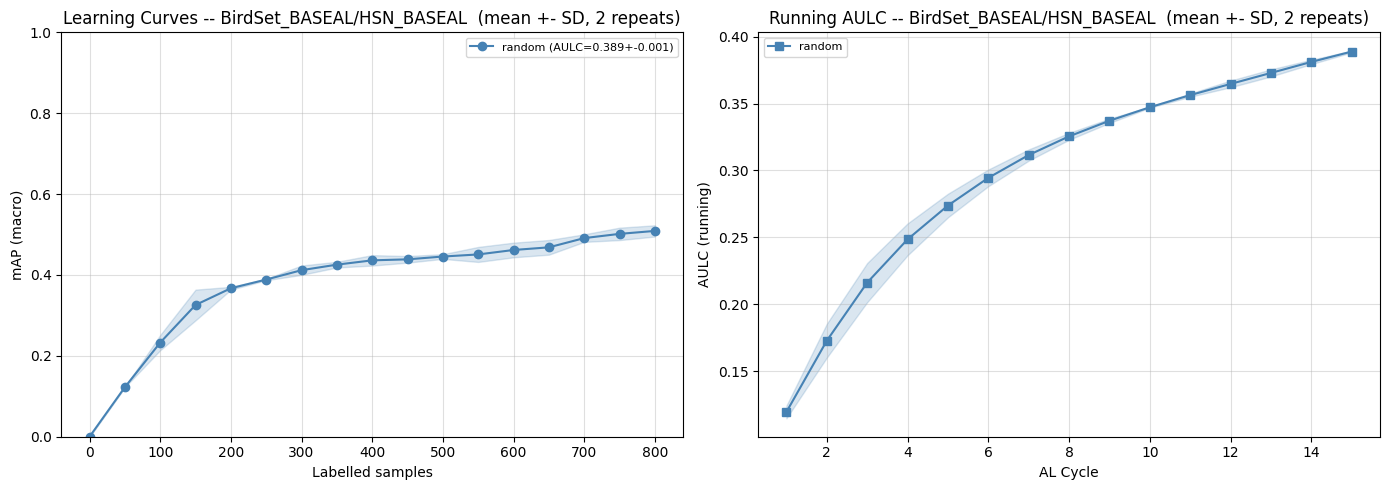


Final results -- BirdSet_BASEAL/HSN_BASEAL  (2 outer repeats)
Strategy                            mAP (mean+-SD)     AULC (mean+-SD)
------------------------------------------------------------------------
random                          0.5089 +-0.0139  0.3889 +-0.0006

Active-testing summary -- random (BirdSet_BASEAL/HSN_BASEAL, 2 outer repeats)
  Cycle   n_lab   n_val   mAP_mean   mAP_est_mean   theta_S  theta_coh         [LCB, UCB]   Winkler
  -------------------------------------------------------------------------------------------------
      1     100     500     0.2328         0.5740    0.5675     0.2006     [0.167, 0.892]    0.7249
      2     150     500     0.3258         0.7620    0.7439     0.2624     [0.231, 0.951]    0.7207
      3     200     500     0.3671         0.7871    0.7746     0.2731     [0.240, 0.958]    0.7183
      4     250     500     0.3887         0.8036    0.7982     0.2814     [0.246, 0.963]    0.7173
      5     300     500     0.4118         0.8170

In [6]:
colors = ['steelblue', 'darkorange', 'seagreen', 'crimson']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for (strategy, histories), color in zip(results.items(), colors):
    agg = aggregate_histories(histories)

    # Include warmup anchor (pretrain_samples, 0.0) when warm-up was applied
    # Aggregate warmup mAP across repeats; origin always stays at (0, 0)
    _wu = [next((e for e in h if e.get('warmup', False)), None) for h in histories]
    _wu = [e for e in _wu if e is not None]
    if _wu:
        x_anchors  = [0, _wu[0]['n_labeled']]
        y_anchors  = [0.0, float(np.mean([e['mAP'] for e in _wu]))]
        sd_anchors = [0.0, float(np.std( [e['mAP'] for e in _wu]))]
    else:
        x_anchors  = [0]
        y_anchors  = [0.0]
        sd_anchors = [0.0]

    n_labeled   = np.array(x_anchors  + [a['n_labeled']    for a in agg])
    mAP_means   = np.array(y_anchors  + [a['mAP_mean']     for a in agg])
    mAP_sds     = np.array(sd_anchors + [a['mAP_sd']       for a in agg])
    aulc_means  = np.array([a['aulc_mAP_mean'] for a in agg])
    aulc_sds    = np.array([a['aulc_mAP_sd']  for a in agg])
    cycles      = np.arange(1, len(aulc_means) + 1)

    final_aulc_mean = agg[-1]['aulc_mAP_mean']
    final_aulc_sd   = agg[-1]['aulc_mAP_sd']
    label = f"{strategy} (AULC={final_aulc_mean:.3f}+-{final_aulc_sd:.3f})"

    # mAP learning curve
    axes[0].plot(n_labeled, mAP_means, marker='o', color=color, label=label)
    axes[0].fill_between(n_labeled,
                         mAP_means - mAP_sds,
                         mAP_means + mAP_sds,
                         alpha=0.2, color=color)

    # Running AULC curve
    axes[1].plot(cycles, aulc_means, marker='s', color=color, label=strategy)
    axes[1].fill_between(cycles,
                         aulc_means - aulc_sds,
                         aulc_means + aulc_sds,
                         alpha=0.2, color=color)

axes[0].set_xlabel('Labelled samples')
axes[0].set_ylabel('mAP (macro)')
axes[0].set_title(f'Learning Curves -- {DATASET_NAME}  (mean +- SD, {N_REPEATS} repeats)')
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.4)

axes[1].set_xlabel('AL Cycle')
axes[1].set_ylabel('AULC (running)')
axes[1].set_title(f'Running AULC -- {DATASET_NAME}  (mean +- SD, {N_REPEATS} repeats)')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print(f"\nFinal results -- {DATASET_NAME}  ({N_REPEATS} outer repeats)")
print(f"{'Strategy':<30}  {'mAP (mean+-SD)':>18}  {'AULC (mean+-SD)':>18}")
print("-" * 72)
for strategy, histories in results.items():
    agg = aggregate_histories(histories)
    final = agg[-1]
    print(f"{strategy:<30}  {final['mAP_mean']:>6.4f} +-{final['mAP_sd']:>6.4f}  "
          f"{final['aulc_mAP_mean']:>6.4f} +-{final['aulc_mAP_sd']:>6.4f}")

# --- Active-testing summary table: mAP_mean (truth) vs mAP_est_mean
# (participant's SCORED-ONLY estimate) and theta_S, plus the full-task,
# range-composed [LCB, UCB] interval, theta_coherent, and the Winkler score
# actually checked against them -- the headline numbers, comparable across
# submissions and ALWAYS real from cycle 1 onward via prevalence-fill (see
# compute_validation_estimate()'s docstring). "--" only applies to the
# scored-only columns (mAP_est_mean/theta_S): no repeat had revealed enough
# validation data to score any class yet at that cycle.
for strategy, histories in results.items():
    agg = aggregate_histories(histories)
    print(f"\nActive-testing summary -- {strategy} ({DATASET_NAME}, {N_REPEATS} outer repeats)")
    print(f"  {'Cycle':>5}  {'n_lab':>6}  {'n_val':>6}  {'mAP_mean':>9}  {'mAP_est_mean':>13}  {'theta_S':>8}  {'theta_coh':>9}  {'[LCB, UCB]':>17}  {'Winkler':>8}")
    print(f"  {'-'*97}")
    for a in agg:
        theta_str = f"{a['mAP_theta_scored_mean']:>8.4f}" if a['mAP_theta_scored_mean'] is not None else f"{'--':>8}"
        est_str   = f"{a['mAP_est_mean']:>13.4f}"          if a['mAP_est_mean']          is not None else f"{'--':>13}"
        # theta_coherent/[LCB, UCB]/Winkler are full-task, range-composed
        # fields -- always real from cycle 1 onward, never "--".
        theta_coh_str = f"{a['theta_coherent_mean']:>9.4f}"
        interval_str  = f"[{a['lcb_mean']:.3f}, {a['ucb_mean']:.3f}]"
        winkler_str   = f"{a['winkler_mean']:>8.4f}"
        print(f"  {a['cycle']:>5}  {a['n_labeled']:>6}  {a['n_validated']:>6}  "
              f"{a['mAP_mean']:>9.4f}  {est_str}  {theta_str}  {theta_coh_str}  {interval_str:>17}  {winkler_str}")


## Step 5: Exported files

Each strategy's results are written to `results/baselines/` as a YAML file.
Inspect these to determine an appropriate `MAX_BUDGET` and confirm baseline performance.

In [7]:
import yaml
from datetime import datetime

_BASELINE_EPOCHS     = 10
_BASELINE_BATCH_SIZE = 32


def _round_or_none(x, ndigits=6):
    return round(x, ndigits) if x is not None else None


def _active_testing_fields(entries):
    """Build the active-testing subset of a learning_curve row (used for
    both the warmup row and each per-cycle row) from a list of per-repeat
    entries at the same point in training. Uses ActiveLearner.agg_mean_sd()
    -- same utility, same sd-is-null-below-2-measurements rule, as
    aggregate_histories()."""
    agg_mean_sd = ActiveLearner.agg_mean_sd
    est_mean,     est_sd,     n_measured = agg_mean_sd(entries, 'mAP_est')
    lcb_s_mean,   lcb_s_sd,   _          = agg_mean_sd(entries, 'lcb_scored')
    ucb_s_mean,   ucb_s_sd,   _          = agg_mean_sd(entries, 'ucb_scored')
    width_s_mean, width_s_sd, _          = agg_mean_sd(entries, 'width_scored')
    theta_mean,   theta_sd,   _          = agg_mean_sd(entries, 'mAP_theta_scored')
    delta_mean,   delta_sd,   _          = agg_mean_sd(entries, 'mAP_theta_scored_delta')
    winkler_mean, winkler_sd, _          = agg_mean_sd(entries, 'winkler')
    lcb_zf_mean,  lcb_zf_sd,  _          = agg_mean_sd(entries, 'lcb_zero_fill')
    lcb_mean,     lcb_sd,     _          = agg_mean_sd(entries, 'lcb')
    ucb_mean,     ucb_sd,     _          = agg_mean_sd(entries, 'ucb')
    theta_coh_mean,       theta_coh_sd,       _ = agg_mean_sd(entries, 'theta_coherent')
    theta_coh_delta_mean, theta_coh_delta_sd, _ = agg_mean_sd(entries, 'theta_coherent_delta')
    return {
        'n_validated':                 entries[0].get('n_validated', 0),
        'mAP_est_mean':                _round_or_none(est_mean),
        'mAP_est_sd':                  _round_or_none(est_sd),
        'lcb_scored_mean':             _round_or_none(lcb_s_mean),
        'lcb_scored_sd':               _round_or_none(lcb_s_sd),
        'ucb_scored_mean':             _round_or_none(ucb_s_mean),
        'ucb_scored_sd':               _round_or_none(ucb_s_sd),
        'width_scored_mean':           _round_or_none(width_s_mean),
        'width_scored_sd':             _round_or_none(width_s_sd),
        'lcb_zero_fill_mean':          _round_or_none(lcb_zf_mean),
        'lcb_zero_fill_sd':            _round_or_none(lcb_zf_sd),
        'lcb_mean':                    _round_or_none(lcb_mean),
        'lcb_sd':                      _round_or_none(lcb_sd),
        'ucb_mean':                    _round_or_none(ucb_mean),
        'ucb_sd':                      _round_or_none(ucb_sd),
        'theta_coherent_mean':         _round_or_none(theta_coh_mean),
        'theta_coherent_sd':           _round_or_none(theta_coh_sd),
        'theta_coherent_delta_mean':   _round_or_none(theta_coh_delta_mean),
        'theta_coherent_delta_sd':     _round_or_none(theta_coh_delta_sd),
        'mAP_theta_scored_mean':       _round_or_none(theta_mean),
        'mAP_theta_scored_sd':         _round_or_none(theta_sd),
        'mAP_theta_scored_delta_mean': _round_or_none(delta_mean),
        'mAP_theta_scored_delta_sd':   _round_or_none(delta_sd),
        'winkler_mean':                _round_or_none(winkler_mean),
        'winkler_sd':                  _round_or_none(winkler_sd),
        # Per-repeat lists, not means -- see aggregate_histories()'s docstring:
        # class-set cardinalities differ between repeats and averaging them
        # is meaningless.
        'n_classes_scored':            [e.get('n_classes_scored', 0)  for e in entries],
        'n_classes_unmeasured':        [e.get('n_classes_unmeasured') for e in entries],
        'n_covered':                   sum(1 for e in entries if e.get('covered') is True),
        'n_repeats_measured':          n_measured,
    }


def export_aggregated(strategy, histories, learner, output_path, max_budget=None):
    """
    Export aggregated (mean +- SD across outer repeats) results as a YAML file.

    The per-cycle learning curve contains mAP and AULC mean/SD, with the warmup
    step included as cycle 0. Supplementary fields include total annotation cost
    and sampling wall-time (mean +- SD across repeats) computed over all history
    entries (warmup + AL cycles) and the standard computational cost ratio.

    Active testing (v2): each learning_curve row carries both families of
    quantities documented in compute_validation_estimate()'s docstring:
      - SCORED-ONLY diagnostics (mAP_est_mean/_sd, lcb_scored_mean/_sd,
        ucb_scored_mean/_sd, width_scored_mean/_sd, mAP_theta_scored and its
        delta from the full-class-set truth) -- None until validation is
        revealed AND clears min_positives_per_class for at least one class,
        and NOT comparable across submissions (different participants can
        score different class sets).
      - FULL-TASK, range-composed fields (lcb_mean/ucb_mean, theta_coherent
        and its delta, winkler_mean, aulc_lcb_mean, and their _sd siblings)
        -- the headline numbers, comparable across submissions, ALWAYS real
        from cycle 1 onward via prevalence-fill: unmeasured/unscored classes
        contribute [prevalence, 1.0] rather than an unknown/null state.
      - lcb_zero_fill_mean/aulc_lcb_zero_fill_mean -- the maximally
        pessimistic companion bound (unmeasured classes contribute 0
        instead of prevalence); a PENALTY, not a confidence bound -- do not
        read it as an LCB.
    mAP_mean/aulc_mAP_mean (unchanged) remain the challenge's official truth
    and ranking metric.

    n_classes_scored/n_classes_unmeasured are per-repeat LISTS (e.g. [3, 2]),
    not means -- each repeat reveals its own independent validation draw and
    so can score a different class set; averaging a set's cardinality across
    repeats that scored different sets is not a meaningful number.
    """
    agg = aggregate_histories(histories)
    model_parameters = int(sum(p.numel() for p in learner.model.parameters()))
    n_cycles = len(agg)
    epochs_per_cycle = EPOCHS_PER_CYCLE

    # Warmup entries (one per outer repeat)
    warmup_entries = [next((e for e in h if e.get('warmup', False)), None) for h in histories]
    warmup_entries = [e for e in warmup_entries if e is not None]

    # Per-cycle rows: warmup as cycle 0, then AL cycles
    learning_curve = []
    if warmup_entries:
        wu_stimes = [e.get('sampling_time_s', 0.0) for e in warmup_entries]
        learning_curve.append({
            'cycle':                 0,
            'warmup':                True,
            'n_labeled':             warmup_entries[0]['n_labeled'],
            'mAP_mean':              round(float(np.mean([e['mAP']      for e in warmup_entries])), 6),
            'mAP_sd':                round(float(np.std( [e['mAP']      for e in warmup_entries])), 6),
            'aulc_mAP_mean':         round(float(np.mean([e['aulc_mAP'] for e in warmup_entries])), 6),
            'aulc_mAP_sd':           round(float(np.std( [e['aulc_mAP'] for e in warmup_entries])), 6),
            'annotation_cost':       warmup_entries[0].get('annotation_cost', 0),
            'sampling_time_s_mean':  round(float(np.mean(wu_stimes)), 6),
            'sampling_time_s_sd':    round(float(np.std(wu_stimes)),  6),
            **_active_testing_fields(warmup_entries),
        })

    for a in agg:
        learning_curve.append({
            'cycle':                       a['cycle'],
            'n_labeled':                   a['n_labeled'],
            'mAP_mean':                    round(a['mAP_mean'],          6),
            'mAP_sd':                      round(a['mAP_sd'],            6),
            'aulc_mAP_mean':               round(a['aulc_mAP_mean'],     6),
            'aulc_mAP_sd':                 round(a['aulc_mAP_sd'],       6),
            'aulc_lcb_mean':               round(a['aulc_lcb_mean'],     6),
            'aulc_lcb_sd':                 round(a['aulc_lcb_sd'],       6),
            'aulc_lcb_scored_mean':        round(a['aulc_lcb_scored_mean'], 6),
            'aulc_lcb_scored_sd':          round(a['aulc_lcb_scored_sd'],   6),
            'aulc_lcb_zero_fill_mean':     round(a['aulc_lcb_zero_fill_mean'], 6),
            'aulc_lcb_zero_fill_sd':       round(a['aulc_lcb_zero_fill_sd'],   6),
            'annotation_cost':             a['annotation_cost'],
            'sampling_time_s_mean':        round(a['sampling_time_s_mean'], 6),
            'sampling_time_s_sd':          round(a['sampling_time_s_sd'],   6),
            'n_validated':                 a['n_validated'],
            'mAP_est_mean':                _round_or_none(a['mAP_est_mean']),
            'mAP_est_sd':                  _round_or_none(a['mAP_est_sd']),
            'lcb_scored_mean':             _round_or_none(a['lcb_scored_mean']),
            'lcb_scored_sd':               _round_or_none(a['lcb_scored_sd']),
            'ucb_scored_mean':             _round_or_none(a['ucb_scored_mean']),
            'ucb_scored_sd':               _round_or_none(a['ucb_scored_sd']),
            'width_scored_mean':           _round_or_none(a['width_scored_mean']),
            'width_scored_sd':             _round_or_none(a['width_scored_sd']),
            'lcb_zero_fill_mean':          _round_or_none(a['lcb_zero_fill_mean']),
            'lcb_zero_fill_sd':            _round_or_none(a['lcb_zero_fill_sd']),
            'lcb_mean':                    _round_or_none(a['lcb_mean']),
            'lcb_sd':                      _round_or_none(a['lcb_sd']),
            'ucb_mean':                    _round_or_none(a['ucb_mean']),
            'ucb_sd':                      _round_or_none(a['ucb_sd']),
            'theta_coherent_mean':         _round_or_none(a['theta_coherent_mean']),
            'theta_coherent_sd':           _round_or_none(a['theta_coherent_sd']),
            'theta_coherent_delta_mean':   _round_or_none(a['theta_coherent_delta_mean']),
            'theta_coherent_delta_sd':     _round_or_none(a['theta_coherent_delta_sd']),
            'mAP_theta_scored_mean':       _round_or_none(a['mAP_theta_scored_mean']),
            'mAP_theta_scored_sd':         _round_or_none(a['mAP_theta_scored_sd']),
            'mAP_theta_scored_delta_mean': _round_or_none(a['mAP_theta_scored_delta_mean']),
            'mAP_theta_scored_delta_sd':   _round_or_none(a['mAP_theta_scored_delta_sd']),
            'winkler_mean':                _round_or_none(a['winkler_mean']),
            'winkler_sd':                  _round_or_none(a['winkler_sd']),
            'n_classes_scored':            a['n_classes_scored'],       # per-repeat list
            'n_classes_unmeasured':        a['n_classes_unmeasured'],   # per-repeat list
            'n_covered':                   a['n_covered'],
            'n_repeats_measured':          a['n_repeats_measured'],
        })

    # Aggregate annotation cost and sampling time across ALL history entries (warmup + AL cycles)
    total_ann_costs = [
        sum(e.get('annotation_cost', 0) for e in h)
        for h in histories
    ]
    total_stimes = [
        sum(e.get('sampling_time_s', 0.0) for e in h)
        for h in histories
    ]

    # Computational cost
    baseline_n_cycles = max_budget // _BASELINE_BATCH_SIZE if max_budget else n_cycles
    cost_method   = model_parameters * epochs_per_cycle * n_cycles
    baseline_cost = model_parameters * _BASELINE_EPOCHS * baseline_n_cycles
    relative_cost = round(cost_method / baseline_cost, 4) if baseline_cost > 0 else None

    final = agg[-1]

    submission = {
        'submission_timestamp':   datetime.now().isoformat(timespec='seconds'),
        'author_lastname':        AUTHOR_LASTNAME,
        'institute_abbreviation': INSTITUTE_ABBREVIATION,
        'sampling_strategy':      strategy,
        'dataset':                DATASET_NAME,
        'model':                  MODEL_NAME,
        'config': {
            'learning_rate':      learner.learning_rate,
            'model_parameters':   model_parameters,
            'n_outer_repeats':    N_REPEATS,
            'pretrain_samples':   learner.pretrain_samples,
            'warmup_strategy':   learner.warmup_strategy.method,
            'validation_strategy':       VALIDATION_STRATEGY,
            'n_validation_samples_per_cycle': None if VALIDATION_SCHEDULER is not None else N_VALIDATION_SAMPLES_PER_CYCLE,
            'validation_scheduler':      VALIDATION_SCHEDULER.__name__ if VALIDATION_SCHEDULER is not None else None,
            'alpha':                     learner.alpha,
            'n_bootstrap':                learner.n_bootstrap,
            'min_positives_per_class':    learner.min_positives_per_class,
        },
        'learning_curve': learning_curve,
        'supplementary': {
            'n_cycles':                       n_cycles,
            'n_outer_repeats':                N_REPEATS,
            'total_annotation_cost_mean':     round(float(np.mean(total_ann_costs)), 2),
            'total_annotation_cost_sd':       round(float(np.std(total_ann_costs)),  2),
            'total_sampling_time_s_mean':     round(float(np.mean(total_stimes)),    6),
            'total_sampling_time_s_sd':       round(float(np.std(total_stimes)),     6),
            'computational_cost': {
                'model_parameters':   model_parameters,
                'epochs_per_cycle':   epochs_per_cycle,
                'n_cycles':           n_cycles,
                'cost_method':        cost_method,
                'baseline_n_cycles':  baseline_n_cycles,
                'baseline_cost':      baseline_cost,
                'relative_cost':      relative_cost,
            },
            # Active testing (v2): final-cycle summary. Budget is NOT
            # currently enforced by this notebook's loop (known, intentional
            # -- see the markdown cell above); n_labeled + n_validated may
            # exceed any nominal MAX_BUDGET at this stage.
            'active_testing': {
                'n_validated_final':          final['n_validated'],
                'aulc_lcb_mean':              round(final['aulc_lcb_mean'], 6),
                'aulc_lcb_sd':                round(final['aulc_lcb_sd'],   6),
                'aulc_lcb_scored_mean':       round(final['aulc_lcb_scored_mean'], 6),
                'aulc_lcb_scored_sd':         round(final['aulc_lcb_scored_sd'],   6),
                'aulc_lcb_zero_fill_mean':    round(final['aulc_lcb_zero_fill_mean'], 6),
                'aulc_lcb_zero_fill_sd':      round(final['aulc_lcb_zero_fill_sd'],   6),
                'mAP_est_mean':               _round_or_none(final['mAP_est_mean']),
                'lcb_scored_mean':            _round_or_none(final['lcb_scored_mean']),
                'ucb_scored_mean':            _round_or_none(final['ucb_scored_mean']),
                'lcb_mean':                   _round_or_none(final['lcb_mean']),
                'ucb_mean':                   _round_or_none(final['ucb_mean']),
                'theta_coherent_mean':        _round_or_none(final['theta_coherent_mean']),
                'winkler_mean':               _round_or_none(final['winkler_mean']),
                'mAP_theta_scored_delta_mean': _round_or_none(final['mAP_theta_scored_delta_mean']),
                'n_classes_scored':           final['n_classes_scored'],      # per-repeat list
                'n_classes_unmeasured':       final['n_classes_unmeasured'],  # per-repeat list
                'n_covered':                  final['n_covered'],
                'n_repeats_measured':         final['n_repeats_measured'],
            },
        },
    }

    Path(output_path).parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, 'w') as f:
        yaml.dump(submission, f, default_flow_style=False, sort_keys=False, allow_unicode=True)
    print(f"  Saved: {Path(output_path).name}")


print(f"Files saved to: {PROJECT_ROOT / 'results' / 'baselines'}\n")
for strategy in STRATEGIES:
    safe_name = DATASET_NAME.replace('/', '_')
    output_file = OUTPUT_DIR / f"{strategy}_{safe_name}.yaml"
    export_aggregated(
        strategy=strategy,
        histories=results[strategy],
        learner=all_learners[strategy],
        output_path=str(output_file),
        max_budget=MAX_BUDGET,
    )


Files saved to: c:\Users\bmcewen\Documents\GitHub\BaseAL\results\baselines

  Saved: random_BirdSet_BASEAL_HSN_BASEAL.yaml


## Notes

- `MAX_BUDGET = None` the loop runs for exactly `N_CYCLES`
- `N_SAMPLES_PER_CYCLE` samples with no cap.
  Set `MAX_BUDGET` to a specific value once an appropriate budget has been determined from these results.
- All four strategies use the same `learning_rate`, `epochs`, and `batch_size` to ensure fair comparison.
- The YAML exports in `results/baselines/` contain the full learning curve and can be used to set
  `MAX_BUDGET` in the challenge participant notebooks.
- **Active testing (v2):** `N_VALIDATION_SAMPLES_PER_CYCLE = 0` (with `VALIDATION_SCHEDULER = None`) recovers the exact original (non-active-testing) behaviour -- no validation samples are ever revealed, and `aulc_lcb`/`aulc_lcb_scored`/`aulc_lcb_zero_fill` all stay 0.0 throughout. `VALIDATION_STRATEGY` currently only ships `"random"`; write a `_custom()` method (mirroring `SamplingStrategy`) for anything more elaborate. `VALIDATION_SCHEDULER` overrides `N_VALIDATION_SAMPLES_PER_CYCLE` when set -- see `validation_scheduler_all_at_start()` for an example of front-loading the whole validation budget instead of spreading it evenly.
- Active-testing fields are computed automatically every cycle by `train_step()` and exported in the YAML, but are **not yet part of the official ranking** -- `aulc_mAP` (unchanged) remains the challenge's official metric.
- **Budget is not currently enforced** by this notebook's loop (known, intentional for now -- it runs a fixed number of cycles for testing). `n_labeled + n_validated` exceeding any nominal `MAX_BUDGET` is expected at this stage.
- **Known, unresolved issue -- LCB curve noise:** in one real run (pre-prevalence-fill, on what is now the `aulc_lcb_scored` curve), `_sd` was ~27% of `_mean` (0.114 on 0.419), versus `aulc_mAP_sd` at ~1.5% of `aulc_mAP_mean`. The LCB curve inherits both retraining variance AND validation-draw variance and is roughly an order of magnitude noisier than `aulc_mAP`; two outer repeats is likely far too few for a usable LCB estimate specifically (`aulc_mAP` itself looked fine at the same N_REPEATS). Not yet re-measured for the full-task `aulc_lcb` (prevalence-fill) -- it may be less noisy, since unmeasured classes now contribute a fixed prevalence rather than nothing, but this hasn't been checked empirically. Reporting as a known limitation pending a decision on how many repeats these fields actually need.
- **Low-sample initiation phase -- now substantially resolved for the full-task fields by prevalence-fill:** with `N_VALIDATION_SAMPLES_PER_CYCLE=10` on a 10-class dataset, `min_positives_per_class=10` can't clear until roughly cycle 10, so the SCORED-ONLY diagnostics (`mAP_est`, `lcb_scored`/`ucb_scored`, and their AULCs) still report unmeasured (None) until then, and the first couple of cycles after that can still be degenerate point-intervals (see the degenerate-bootstrap guard in `compute_validation_estimate()`) -- that part of the issue is unchanged. But the full-task, range-composed fields (`lcb`/`ucb`/`theta_coherent`/`winkler`/`aulc_lcb`) no longer sit in a null "unmeasured" state during this phase: every class that hasn't cleared the threshold contributes `[prevalence, 1.0]` from cycle 1 onward, so the headline interval is real (if wide) throughout. **Confirm before ripping anything out:** whether `min_positives_per_class`/the scored-class-set `S` machinery is still load-bearing now that the full-task fields don't depend on it clearing early, or whether it can eventually be simplified to a purely diagnostic threshold -- flagged as something to confirm against more real runs, not something to act on unilaterally.
